# N_g = 4–7 精度 / 计算代价基准测试（Reviewer #3, Comment 3）

In [97]:
import os
os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')
os.environ.setdefault('OMP_NUM_THREADS', '8')

import sys, csv, time, importlib.util
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

def locate_project_root() -> Path:
    candidates = [Path.cwd().resolve(), Path.cwd().resolve().parent,
                  Path.cwd().resolve().parent.parent]
    for candidate in candidates:
        if (candidate / "src" / "generate_validation_plots.py").exists():
            return candidate
    raise FileNotFoundError("Could not locate project root from the current notebook working directory.")

PROJECT_ROOT = locate_project_root()
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / "src"))

spec = importlib.util.spec_from_file_location("gvp", PROJECT_ROOT / "src" / "generate_validation_plots.py")
gvp = importlib.util.module_from_spec(spec)
assert spec.loader is not None
spec.loader.exec_module(gvp)

from src.utils import read_from_excel          # pandas only, no torch needed

print(f"Project root: {PROJECT_ROOT}")

Project root: E:\Project\JupyterProjects\RSM_WSGG


## §1 参数配置改这一格就够了，后面所有格子都依赖它。

In [98]:
# ---- 要比较的灰气体条数 ----
NG_LIST = [4, 5, 6, 7]

# ---- 验证集（独立 emissivity 数据库）----
DATASET = PROJECT_ROOT / "input" / "MixEmiss_p1.0_X0.2_Mr0.1-4.0_15_T22_path40.npy"
if not DATASET.exists():                       # 退回脚本里的默认独立验证集
    DATASET = gvp.DEFAULT_VALIDATION_DATASET

# ---- RTE 计时用的非等温算例 ----
CASES_DIR = PROJECT_ROOT / "input" / "profiles"

# ---- 物理参数（与正文一致）----
PT = 1.0
X = 0.2
T_REF = 1000.0
BOUNDARY_TEMPERATURE = 300.0

# ---- 计时设置 ----
REPEAT = 5        # 重复次数，报告最小值
WARMUP = 1        # 预热次数（numba JIT / 页缓存）
SKIP_TRANSPARENT = False   # 跳过 kappa=0 的透明灰气体（数值精确，省 1/(N_g+1)）

# ---- 系数文件 ----
# 留空则按 _Ng{n}_ 自动发现；也可显式指定，例如
#   COEFF_MAP = {6: PROJECT_ROOT / "results" / "coefficients_20260326_122927_Ng6_Exp4_Tref1000_bs16384.xlsx"}
COEFF_MAP: Dict[int, Path] = {}
COEFF_DIR  = PROJECT_ROOT / "results"
COEFF_PATTERN = "coefficients_*.xlsx"

# ---- 输出 ----
OUTPUT_DIR = PROJECT_ROOT / "results" / "ng_benchmark"

print(f"Dataset : {DATASET}")
print(f"Exists  : {DATASET.exists()}")

Dataset : E:\Project\JupyterProjects\RSM_WSGG\input\MixEmiss_p1.0_X0.2_Mr0.1-4.0_15_T22_path40.npy
Exists  : True


## §2 加载数据

In [99]:
if not DATASET.exists():
    raise FileNotFoundError(f"Validation dataset not found: {DATASET}")

case_files = sorted(CASES_DIR.glob("Case*.npy"), key=gvp.case_sort_key)
if not case_files:
    raise FileNotFoundError(f"No Case*.npy found in {CASES_DIR}")

mole_ratios, temperatures, path_lengths, reference = gvp.load_emissivity_cube(DATASET)

print(f"Reference cube : {reference.shape}  (Mr x T x L)")
print(f"Mr  {mole_ratios.min():.2f} - {mole_ratios.max():.2f}  ({len(mole_ratios)})")
print(f"T   {temperatures.min():.0f} - {temperatures.max():.0f} K  ({len(temperatures)})")
print(f"L   {path_lengths.min():.2f} - {path_lengths.max():.2f} m  ({len(path_lengths)})")
print(f"Cases          : {[p.stem for p in case_files]}")
print(f"Transparent gas: {'skipped' if SKIP_TRANSPARENT else 'solved (as published)'}")

Reference cube : (15, 22, 40)  (Mr x T x L)
Mr  0.10 - 4.00  (15)
T   300 - 2400 K  (22)
L   0.02 - 58.51 m  (40)
Cases          : ['Case1.1_L1.0m', 'Case1.2_L1.0m', 'Case1.3_L1.0m', 'Case2.1_L1.0m', 'Case2.2_L1.0m', 'Case3.1_L1.0m', 'Case3.2_L1.0m', 'Case4.1_L1.0m', 'Case4.2_L5.0m']
Transparent gas: solved (as published)


## §3 发现 / 指定系数文件`beta` 应有 `N_g + 1` 行（第 0 行是透明气体 κ=0），`gamma` 同。

In [100]:
def discover_coefficients(results_dir: Path, ng: int, pattern: str) -> Optional[Path]:
    matches = [p for p in results_dir.glob(pattern)
               if f"_Ng{ng}_" in p.name or p.name.endswith(f"_Ng{ng}.xlsx")]
    return max(matches, key=lambda item: item.stat().st_mtime) if matches else None


resolved: Dict[int, Path] = {}
for ng in sorted(NG_LIST):
    path = COEFF_MAP.get(ng) or discover_coefficients(COEFF_DIR, ng, COEFF_PATTERN)
    if path is None:
        print(f"[warn] N_g={ng}: no coefficient file found in {COEFF_DIR}")
        continue
    resolved[ng] = path
    print(f"N_g={ng}: {path.name}")

print()
print("available coefficient files:")
for p in sorted(COEFF_DIR.glob(COEFF_PATTERN)):
    print("   ", p.name)

N_g=4: coefficients_20261006_051946_Ng4_Exp4_Tref1000_bs8192.xlsx
N_g=5: coefficients_20261007_114635_Ng5_Exp4_Tref1000_bs32768.xlsx
N_g=6: coefficients_20260326_122927_Ng6_Exp4_Tref1000_bs16384.xlsx
N_g=7: coefficients_20261007_223417_Ng7_Exp4_Tref1000_bs32768.xlsx

available coefficient files:
    coefficients_20260326_122927_Ng6_Exp4_Tref1000_bs16384.xlsx
    coefficients_20261006_051946_Ng4_Exp4_Tref1000_bs8192.xlsx
    coefficients_20261007_114635_Ng5_Exp4_Tref1000_bs32768.xlsx
    coefficients_20261007_223417_Ng7_Exp4_Tref1000_bs32768.xlsx


## §4 精度评估（拟合误差）

In [101]:
def accuracy_metrics(reference: np.ndarray, prediction: np.ndarray) -> Dict[str, float]:
    residual = prediction - reference
    denominator = np.clip(np.abs(reference), 1e-8, None)
    relative = np.abs(residual) / denominator
    return {
        "loss_mse": float(np.mean((residual / denominator) ** 2)),
        "mae": float(np.mean(np.abs(residual))),
        "maxae": float(np.max(np.abs(residual))),
        "pct_within_5": float(np.mean(relative <= 0.05) * 100.0),
        "pct_within_10": float(np.mean(relative <= 0.10) * 100.0),
    }


rows: List[Dict[str, float]] = []
source_beta = source_gamma = None

for ng, coeff_path in sorted(resolved.items()):
    beta, gamma = read_from_excel(str(coeff_path))
    beta = np.asarray(beta, dtype=float)
    gamma = np.asarray(gamma, dtype=float)
    if beta.shape[0] != ng + 1:
        print(f"[warn] {coeff_path.name}: beta has {beta.shape[0]} rows, expected N_g+1={ng+1} -- skipped")
        continue

    prediction = gvp.predict_rsm_emissivity_cube(
        mole_ratios, temperatures, path_lengths, beta, gamma, PT, X, T_REF
    )
    acc = accuracy_metrics(reference, prediction)
    source_beta, source_gamma = beta, gamma

    rows.append({"Ng": ng, "coefficients": coeff_path.name, "rte_source": "fitted", **acc})
    print(f"N_g={ng}: loss={acc['loss_mse']:.3e}  <=5%={acc['pct_within_5']:.1f}%  "
          f"<=10%={acc['pct_within_10']:.1f}%")

print(f"\nevaluated {len(rows)} coefficient set(s)")

N_g=4: loss=4.239e-04  <=5%=97.3%  <=10%=99.8%
N_g=5: loss=2.899e-04  <=5%=98.9%  <=10%=99.9%
N_g=6: loss=2.163e-04  <=5%=99.1%  <=10%=100.0%
N_g=7: loss=8.122e-05  <=5%=99.9%  <=10%=100.0%

evaluated 4 coefficient set(s)


## §5 RTE 计时单次 RTE 求解的耗时只取决于**灰气体条数和网格点数**，与吸收系数的数值无关。所以即使某个 N_g 的模型还没训出来，也可以把已有系数**平铺**到 N_g+1 行来实测耗时（row 0 保持透明气体，使参与求解的恰好是 N_g 条）。

In [102]:
def solve_case(profile, beta, gamma, t_ref, boundary_temperature, skip_transparent):
    '''Same physics as gvp.wsgg_rsm_case_solution with an optional shortcut.'''
    from scipy.constants import sigma

    xs = profile["x"]
    temperature_profile = profile["T"]
    x_h2o = profile["Y_H2O"]
    x_nh3 = profile["Y_NH3"] + 1e-4

    gray_count = beta.shape[0]
    weights = np.zeros((len(xs), gray_count), dtype=float)
    absorption = np.zeros((len(xs), gray_count), dtype=float)
    for index in range(len(xs)):
        weights[index], absorption[index] = gvp.get_k_a_ml(
            temperature_profile[index] / t_ref,
            float(x_h2o[index] / x_nh3[index]), beta, gamma,
        )
    absorption *= (x_h2o + x_nh3).reshape(-1, 1)

    total_q = np.zeros(len(xs), dtype=float)
    total_dq = np.zeros(len(xs), dtype=float)
    used = 0
    for gas_index in range(gray_count):
        if skip_transparent and np.allclose(absorption[:, gas_index], 0.0, atol=1e-14):
            continue
        i_b = sigma * np.power(temperature_profile, 4) * weights[:, gas_index] / np.pi
        i_b_left = sigma * boundary_temperature ** 4 * weights[0, gas_index] / np.pi
        i_b_right = sigma * boundary_temperature ** 4 * weights[-1, gas_index] / np.pi
        _, q, dq = gvp.solver.solve_rte(xs, absorption[:, gas_index], i_b, i_b_left, i_b_right)
        total_q += q
        total_dq += dq
        used += 1
    return total_q, total_dq, used


def measure_runtime(case_files, beta, gamma, t_ref, boundary_temperature,
                    repeat=REPEAT, warmup=WARMUP, skip_transparent=SKIP_TRANSPARENT):
    profiles = [np.load(p, allow_pickle=False) for p in case_files]

    def one_pass():
        start = time.perf_counter()
        for profile in profiles:
            solve_case(profile, beta, gamma, t_ref, boundary_temperature, skip_transparent)
        return time.perf_counter() - start

    for _ in range(max(0, warmup)):
        one_pass()
    samples = [one_pass() for _ in range(max(1, repeat))]
    best = float(np.min(samples))
    return {"total_s": best,
            "per_case_ms": best / max(1, len(case_files)) * 1000.0,
            "std_s": float(np.std(samples))}

In [103]:
def build_synthetic_coefficients(beta: np.ndarray, gamma: np.ndarray, ng: int):
    '''Tile an existing coefficient set so that exactly N_g gases participate.'''
    if beta.shape[0] < 2:
        raise ValueError("Source coefficient set must contain at least one participating gas.")

    def tile(source: np.ndarray, rows: int) -> np.ndarray:
        transparent = source[0:1]
        participating = source[1:]
        repeats = int(np.ceil(rows / max(1, participating.shape[0])))
        pool = np.vstack([participating] * repeats)
        return np.vstack([transparent, pool[: rows - 1]])

    return tile(beta, ng + 1), tile(gamma, ng + 1)

### 5.1 对已训好的系数计时

In [104]:
coeff_cache = {}
for ng, coeff_path in sorted(resolved.items()):
    beta, gamma = read_from_excel(str(coeff_path))
    coeff_cache[ng] = (np.asarray(beta, float), np.asarray(gamma, float))

for ng in sorted(coeff_cache):
    beta, gamma = coeff_cache[ng]
    if beta.shape[0] != ng + 1:
        continue
    t = measure_runtime(case_files, beta, gamma, T_REF, BOUNDARY_TEMPERATURE)
    for row in rows:
        if int(row["Ng"]) == ng:
            row.update(rte_total_s=t["total_s"], rte_per_case_ms=t["per_case_ms"],
                       rte_std_s=t["std_s"], rte_source="fitted")
    print(f"[fitted]    N_g={ng}: {t['per_case_ms']:.3f} ms/case "
          f"(total {t['total_s']:.4f} s, std {t['std_s']:.4f})")

[fitted]    N_g=4: 50.509 ms/case (total 0.4546 s, std 0.0125)
[fitted]    N_g=5: 60.222 ms/case (total 0.5420 s, std 0.0039)
[fitted]    N_g=6: 69.359 ms/case (total 0.6242 s, std 0.0401)
[fitted]    N_g=7: 79.177 ms/case (total 0.7126 s, std 0.0088)


### 5.2 synthetic timing（N_g 未训好时用它把耗时列填满）`USE_SYNTHETIC_TIMING = True` 会对 **NG_LIST 里每一个** N_g 实测耗时并写入表格。

In [105]:
USE_SYNTHETIC_TIMING = True      # ← 改这里
SYNTHETIC_FOR_ALL = False        # True: 覆盖全部 N_g; False: 只补缺失的 N_g（推荐，不覆盖实测值）

if USE_SYNTHETIC_TIMING:
    if source_beta is None:
        fallback = sorted(COEFF_DIR.glob(COEFF_PATTERN))
        if not fallback:
            raise SystemExit("synthetic timing needs at least one coefficient file to tile")
        source_beta, source_gamma = read_from_excel(str(fallback[-1]))
        source_beta = np.asarray(source_beta, float)
        source_gamma = np.asarray(source_gamma, float)
        print(f"[synthetic] tiling: {fallback[-1].name}")

    by_ng = {int(r["Ng"]): r for r in rows}
    for ng in sorted(NG_LIST):
        if ng in by_ng and not SYNTHETIC_FOR_ALL:
            continue
        sbeta, sgamma = build_synthetic_coefficients(source_beta, source_gamma, ng)
        t = measure_runtime(case_files, sbeta, sgamma, T_REF, BOUNDARY_TEMPERATURE)
        payload = dict(rte_total_s=t["total_s"], rte_per_case_ms=t["per_case_ms"],
                       rte_std_s=t["std_s"], rte_source="synthetic-probe")
        if ng in by_ng:
            by_ng[ng].update(payload)
        else:
            rows.append({"Ng": ng, "coefficients": "(cost probe, not fitted)",
                         "loss_mse": float("nan"), "mae": float("nan"), "maxae": float("nan"),
                         "pct_within_5": float("nan"), "pct_within_10": float("nan"),
                         "rte_source": "synthetic-probe", **payload})
        print(f"[synthetic] N_g={ng}: {t['per_case_ms']:.3f} ms/case (total {t['total_s']:.4f} s)")

    rows.sort(key=lambda r: int(r["Ng"]))

## §6 汇总表

In [106]:
missing = [r["Ng"] for r in rows if not np.isfinite(r.get("rte_total_s", float("nan")))]
if missing:
    raise RuntimeError(f"No runtime measured for N_g={missing}; run §5 first.")

base_time = min(r["rte_total_s"] for r in rows)
for r in rows:
    r["rel_time"] = r["rte_total_s"] / base_time

COLUMNS = ["Ng", "coefficients", "loss_mse", "mae", "maxae",
           "pct_within_5", "pct_within_10",
           "rte_per_case_ms", "rte_std_s", "rel_time", "rte_source"]

df = pd.DataFrame(rows)[COLUMNS]
display(df.style.format({
    "loss_mse": "{:.3e}", "mae": "{:.3e}", "maxae": "{:.3e}",
    "pct_within_5": "{:.2f}", "pct_within_10": "{:.2f}",
    "rte_per_case_ms": "{:.3f}", "rte_std_s": "{:.4f}", "rel_time": "{:.3f}",
}).hide(axis="index"))

# 线性拟合 t(N_g) = a + b*N_g，用来说明代价确实是线性的
ng_arr = np.array([r["Ng"] for r in rows], float)
tt_arr = np.array([r["rte_total_s"] for r in rows], float)
b, a = np.polyfit(ng_arr, tt_arr, 1)
pred = a + b * ng_arr
r2 = 1.0 - np.sum((tt_arr - pred) ** 2) / np.sum((tt_arr - tt_arr.mean()) ** 2)
print(f"linear fit: t(N_g) = {a:.4f} + {b:.4f} * N_g   (R^2 = {r2:.4f})")
print(f"implied relative cost 4->7: {(a + b*7) / (a + b*4):.3f}")

Ng,coefficients,loss_mse,mae,maxae,pct_within_5,pct_within_10,rte_per_case_ms,rte_std_s,rel_time,rte_source
4,coefficients_20261006_051946_Ng4_Exp4_Tref1000_bs8192.xlsx,4.239e-04,6.689e-03,5.614e-02,97.33,99.82,50.509,0.0125,1.000,fitted
5,coefficients_20261007_114635_Ng5_Exp4_Tref1000_bs32768.xlsx,2.899e-04,5.189e-03,4.106e-02,98.89,99.91,60.222,0.0039,1.192,fitted
6,coefficients_20260326_122927_Ng6_Exp4_Tref1000_bs16384.xlsx,2.163e-04,4.548e-03,4.031e-02,99.08,99.99,69.359,0.0401,1.373,fitted
7,coefficients_20261007_223417_Ng7_Exp4_Tref1000_bs32768.xlsx,8.122e-05,3.097e-03,2.547e-02,99.86,100.00,79.177,0.0088,1.568,fitted


linear fit: t(N_g) = 0.1124 + 0.0856 * N_g   (R^2 = 0.9998)
implied relative cost 4->7: 1.565


## §7 输出 csv / LaTeX / 图

In [107]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- csv ----
csv_path = OUTPUT_DIR / "ng_benchmark.csv"
with csv_path.open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0].keys()))
    writer.writeheader()
    writer.writerows(rows)
print(f"Saved {csv_path}")

# ---- LaTeX ----
def loss_cell(value):
    if not np.isfinite(value) or value <= 0:
        return "--"
    exponent = int(np.floor(np.log10(value)))
    return f"{value / 10.0 ** exponent:.2f}$\\times 10^{{{exponent}}}$"

tex_lines = [r"\hline",
             "$N_g$ & Validation loss & Points with error $\\leq$ 5\\% (\\%) "
             "& Points with error $\\leq$ 10\\% (\\%) & Relative RTE time \\\\",
             r"\hline"]
for r in rows:
    if np.isfinite(r["loss_mse"]) and r["loss_mse"] > 0:
        c5, c10, cl = f"{r['pct_within_5']:.1f}", f"{r['pct_within_10']:.1f}", loss_cell(r["loss_mse"])
    else:
        cl = c5 = c10 = "--"
    tex_lines.append(f"{int(r['Ng'])} & {cl} & {c5} & {c10} & {r['rel_time']:.2f} \\\\")
tex_lines.append(r"\hline")

tex_path = OUTPUT_DIR / "ng_benchmark.tex"
tex_path.write_text("\n".join(tex_lines) + "\n", encoding="utf-8")
print(f"Saved {tex_path}")
print()
print("\n".join(tex_lines))

Saved E:\Project\JupyterProjects\RSM_WSGG\results\ng_benchmark\ng_benchmark.csv
Saved E:\Project\JupyterProjects\RSM_WSGG\results\ng_benchmark\ng_benchmark.tex

\hline
$N_g$ & Validation loss & Points with error $\leq$ 5\% (\%) & Points with error $\leq$ 10\% (\%) & Relative RTE time \\
\hline
4 & 4.24$\times 10^{-4}$ & 97.3 & 99.8 & 1.00 \\
5 & 2.90$\times 10^{-4}$ & 98.9 & 99.9 & 1.19 \\
6 & 2.16$\times 10^{-4}$ & 99.1 & 100.0 & 1.37 \\
7 & 8.12$\times 10^{-5}$ & 99.9 & 100.0 & 1.57 \\
\hline


Saved E:\Project\JupyterProjects\RSM_WSGG\results\ng_benchmark\ng_benchmark.png


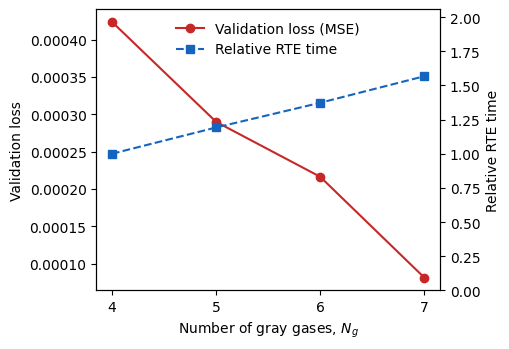

In [108]:
# ---- figure ----
fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.plot([r["Ng"] for r in rows], [r["loss_mse"] for r in rows],
        "o-", color="#C62828", label="Validation loss (MSE)")
ax.set_xlabel(r"Number of gray gases, $N_g$")
ax.set_ylabel("Validation loss")
ax.set_xticks([r["Ng"] for r in rows])

ax2 = ax.twinx()
ax2.plot([r["Ng"] for r in rows], [r["rel_time"] for r in rows],
         "s--", color="#1565C0", label="Relative RTE time")
ax2.set_ylabel("Relative RTE time")
ax2.set_ylim(0.0, max(r["rel_time"] for r in rows) * 1.25 + 0.1)

h = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
l = ax.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax.legend(h, l, loc="upper center", frameon=False)
fig.tight_layout()

png_path = OUTPUT_DIR / "ng_benchmark.png"
fig.savefig(png_path, dpi=400)
print(f"Saved {png_path}")
plt.show()